# Solar filament segmentation: the full pipeline

This notebook runs our final pipeline for the Filament Segmentation Challenge 2026 from the raw competition data to `submission.csv`. The score is Panoptic Quality (PQ) at IoU 0.5, computed with the organisers' scorer. The pipeline scores **0.4571 out-of-fold PQ** on all 707 train observations and was submitted as Kaggle reference 57096818 (public leaderboard 0.39).

The pipeline has six steps. Step 1 reads the data and finds the solar disk in every image. Step 2 trains three whole-disk ConvNeXt-Tiny U-Nets with five folds each. Step 3 predicts probability maps with an 8-way flip and rotation average. Step 4 cuts every map into candidate filaments and scores each candidate with a small CNN quality head. Step 5 fuses the candidates of the three models at the filament level and writes the submission. Step 6 evaluates the out-of-fold result with the official scorer and draws the plots the judges use.

Training needs about 30 GPU hours, so the notebook has switches. With the defaults it skips training and inference and starts from saved probability maps, which takes about 25 minutes on a laptop (Apple M-series, peak memory 5 GB). With `RUN_INFERENCE = True` it predicts the maps from the 15 saved checkpoints on a Kaggle 2xT4 kernel. With `RUN_TRAINING = True` it also trains every model from scratch.

## 0. Settings

All paths and switches are in the next cell. Every switch can also be set with an environment variable of the same name and the prefix `FIL_`, so a test run does not need an edit. The code lives in `src/` next to this notebook and is imported from there. On Kaggle, attach this repository as a dataset and set `RELEASE` to the folder that holds `src/`.

In [1]:
import json, os, subprocess, sys, threading, time
from pathlib import Path


def env(name, default):
    v = os.environ.get("FIL_" + name)
    if v is None:
        return default
    return type(default)(int(v)) if isinstance(default, bool) else type(default)(v) if default is not None else v


ON_KAGGLE = Path("/kaggle/input").exists()
RELEASE = Path(env("RELEASE", str(Path.cwd())))       # folder with this notebook, src/ and data/meta.json
SRC = RELEASE / "src"
if ON_KAGGLE:  # the competition data, wherever Kaggle mounts it
    _ann = sorted(Path("/kaggle/input").glob("**/MAGFiLO_1.0_Annotations_kaggle2026_train.json"))
    _default_data = str(_ann[0].parents[1]) if _ann else "/kaggle/input/filament-segmentation-2026"
else:
    _default_data = str(RELEASE.parent / "data" / "MAGFiLO_1.0_Kaggle_2026")
DATA_DIR = Path(env("DATA_DIR", _default_data))
WORK = Path(env("WORK", "/kaggle/working" if ON_KAGGLE else str(RELEASE / "work")))

RUN_TRAINING = env("RUN_TRAINING", False)     # about 30 GPU hours (section 2)
RUN_INFERENCE = env("RUN_INFERENCE", False)   # about 3 GPU hours on 2xT4 with the 15 checkpoints (section 3)
TRAIN_CNN_HEAD = env("TRAIN_CNN_HEAD", False) # about 35 minutes on an Apple GPU; False loads the saved head
HEAD_EPOCHS = env("HEAD_EPOCHS", 12)
SUBSET = env("SUBSET", 0) or None             # an integer runs steps 4 to 6 on the first N train and test images
WORKERS = env("WORKERS", 4)

# Checkpoints of the Kaggle training kernels, mounted as notebook inputs (section 3).
WEIGHTS_DIR = Path(env("WEIGHTS_DIR", "/kaggle/input" if ON_KAGGLE else str(RELEASE / "weights")))
# Saved maps and CNN head of the research runs, used when inference or head training is skipped.
SAVED = Path(env("SAVED", str(RELEASE.parent / "outputs")))
# Optional table whose rows fill test images where no model finds any candidate (section 5).
FALLBACK_CSV = env("FALLBACK_CSV", "")

sys.path.insert(0, str(SRC))
WORK.mkdir(parents=True, exist_ok=True)
print("data", DATA_DIR, "| work", WORK, "| training", RUN_TRAINING, "| inference", RUN_INFERENCE,
      "| head training", TRAIN_CNN_HEAD, "| subset", SUBSET)

data /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026 | work /kaggle/temp/work | training False | inference True | head training False | subset None


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt

from common import N_FOLDS, find_disk, fold_of, read_gray
from data import build_meta, gt_rles, gt_table, image_path, load_index, test_images
import cnn_head
import fusion
from fast_pq import pq
from self_eval import evaluate, to_frame
from organiser_plots import plot_distribution, plot_m2n_counts

print("python", sys.version.split()[0], "| torch", torch.__version__, "| cuda GPUs", torch.cuda.device_count(),
      "| mps", torch.backends.mps.is_available())

python 3.13.15 | torch 2.11.0+cu128 | cuda GPUs 2 | mps False


## 1. Data and solar-disk geometry

The train set has 707 observations (images) with 1,154 annotator-images, because most images were drawn by two or three annotators. All annotators of one image always share a fold, and the fold is a hash of the observation name. The ground truth is rebuilt here from the COCO polygons in the official RLE format, with one row per filament and the id `<annotator>-<observation>_<annotation>`.

Post-processing needs the centre and radius of the solar disk in each image, and drops any candidate whose centre lies outside it. `find_disk` takes the minimum enclosing circle of the largest region brighter than 30. On many frames this circle fits the grey halo around the Sun and runs up to about 15 per cent too large, so the limb rule removes almost nothing. We kept it because every result in this notebook was scored with it. The disks of all 887 images are frozen in `data/meta.json`, and the cell below detects a few of them again and checks that they match.

In [3]:
index = load_index(DATA_DIR)
tests = test_images(DATA_DIR)
meta = json.load(open(RELEASE / "data" / "meta.json"))
assert set(index) == set(meta["train"]) and set(tests) == set(meta["test"]), "meta.json does not match the data"
n_ann = sum(len(v["annotators"]) for v in index.values())
print(f"{len(index)} train observations, {n_ann} annotator-images, {len(tests)} test images")
print("observations per fold:", np.bincount([fold_of(o) for o in index]).tolist())

check = list(index)[:3] + tests[:3]
fresh = build_meta(DATA_DIR, index, check[:3], check[3:], workers=min(WORKERS, 3))
diff = max(np.abs(np.subtract(fresh[s][k]["disk"], meta[s][k]["disk"])).max()
           for s, ks in (("train", check[:3]), ("test", check[3:])) for k in ks)
print(f"largest difference between fresh and frozen disk geometry on {len(check)} images: {diff:.4f} pixels")

707 train observations, 1154 annotator-images, 180 test images
observations per fold: [139, 146, 132, 146, 144]


largest difference between fresh and frozen disk geometry on 6 images: 0.0000 pixels


In [4]:
oof_keys = sorted(index)[:SUBSET] if SUBSET else sorted(index)
test_keys = tests[:SUBSET] if SUBSET else tests
gt_df = gt_table(index, oof_keys)
gt = gt_rles(gt_df)
print(f"steps 4 to 6 use {len(oof_keys)} train observations ({len(gt_df)} ground-truth filaments) and {len(test_keys)} test images")

steps 4 to 6 use 707 train observations (8199 ground-truth filaments) and 180 test images


## 2. Training the three U-Nets (GPU, about 30 hours)

All three models are the same network: a ConvNeXt-Tiny encoder from timm with a five-stage U-Net decoder and two output channels (filament and filament outline). The network sees the whole solar disk at once. Smaller crops lost the context of the full disk, and every step up in input size helped (512 crops 0.409, whole disk at 1536 0.4416 OOF). Each training sample uses the mask of one randomly chosen annotator, with random rotations, flips and mild brightness, blur and noise changes. The loss is binary cross-entropy plus soft Dice on the filament channel and weighted cross-entropy on the outline channel. An exponential moving average (EMA) of the weights is kept and saved.

| Model | Recipe | Kaggle kernels that trained it |
| --- | --- | --- |
| `g1536a` | seed 0, `convnext_tiny.in12k_ft_in1k`, 30 epochs at 1024 then 24 at 1536 | `filament-db1-global1536` (fold 0), `filament-g1536-f12`, `filament-g1536-f34` |
| `g1536b` | seed 7, `convnext_tiny.fb_in22k_ft_in1k`, same schedule | `filament-g1536b-f01`, `filament-g1536b-f23`, `filament-g1536b-f4` |
| `g2048` | `g1536a` checkpoints fine-tuned 10 more epochs at 2048, lr 5e-5 | `filament-g2048-f01`, `filament-g2048-f23`, `filament-g2048-f4` |

One fold of a 1536 model takes about 2 hours on one T4, and the 2048 fine-tune about 1.2 hours. The code runs one fold per GPU, so a 2xT4 kernel trains two folds at once. A Kaggle session stops after 12 hours, so set `TRAIN_JOBS` to a slice of the job list and run the notebook several times, keeping `WORK/ckpt` between sessions. Training uses float16 autocast and cuDNN autotuning, so a rerun gives close but not bit-identical weights.

In [5]:
MODELS = {  # name: (seed, encoder weights tried first, inference resolution)
    "g1536a": (0, "", 1536),
    "g1536b": (7, "convnext_tiny.fb_in22k_ft_in1k", 1536),
    "g2048": (0, "", 2048),
}
CKPT_NAME = {"g1536a": "ema_stage2_1536.pt", "g1536b": "ema_stage2_1536.pt", "g2048": "ema_stage3_2048.pt"}
N_GPU = max(torch.cuda.device_count(), 1)


def run_jobs(jobs, tag):
    # Runs each job (a list of global_unet.py arguments) as its own process, one queue per GPU.
    queues = [jobs[i::N_GPU] for i in range(N_GPU)]
    (WORK / "logs").mkdir(exist_ok=True)
    codes = []

    def worker(gpu, queue):
        for i, args in enumerate(queue):
            logf = WORK / "logs" / f"{tag}_gpu{gpu}_{i}.log"
            e = {**os.environ, "CUDA_VISIBLE_DEVICES": str(gpu)}
            with open(logf, "w") as f:
                r = subprocess.run([sys.executable, str(SRC / "global_unet.py"), *args], env=e, stdout=f, stderr=subprocess.STDOUT)
            codes.append((args[0], args[args.index("--fold") + 1], r.returncode, str(logf)))

    threads = [threading.Thread(target=worker, args=(g, q)) for g, q in enumerate(queues)]
    [t.start() for t in threads]
    [t.join() for t in threads]
    for c in codes:
        print(c)
    assert all(c[2] == 0 for c in codes), "a job failed, see its log"


def own_ckpt(model, fold):
    return WORK / "ckpt" / model / f"fold{fold}" / CKPT_NAME[model]


if RUN_TRAINING:
    jobs = []
    for m in ("g1536a", "g1536b"):
        seed, weights, _ = MODELS[m]
        for k in range(N_FOLDS):
            if not own_ckpt(m, k).exists():
                jobs.append(["train", "--data", str(DATA_DIR), "--fold", str(k), "--out", str(own_ckpt(m, k).parent),
                             "--seed", str(seed)] + (["--weights", weights] if weights else []))
    jobs = jobs[slice(*map(int, env("TRAIN_JOBS", "0:100").split(":")))]
    run_jobs(jobs, "train")
    jobs = [["finetune", "--data", str(DATA_DIR), "--fold", str(k), "--out", str(own_ckpt("g2048", k).parent),
             "--ckpt", str(own_ckpt("g1536a", k))] for k in range(N_FOLDS)
            if own_ckpt("g1536a", k).exists() and not own_ckpt("g2048", k).exists()]
    run_jobs(jobs, "finetune")
else:
    print("training skipped (RUN_TRAINING = False)")

training skipped (RUN_TRAINING = False)


## 3. Checkpoints and 8-way inference (GPU, about 3 hours)

Without training, the weights come from the public Kaggle dataset [pragyaangaur/filament-segmentation-2026-weights](https://www.kaggle.com/datasets/pragyaangaur/filament-segmentation-2026-weights). It holds the 15 U-Net checkpoints as `<model>_fold<k>.pt` and the 10 CNN quality heads. Add it as an input of the Kaggle notebook, or download it into `weights/` next to this notebook, and the cell below finds the files. The same checkpoints are also outputs of the Kaggle kernels in the table of section 2, and adding those kernels as inputs works too. Kaggle mounts each one under `/kaggle/input/<kernel name>/`, and the cell below finds every checkpoint by its path inside the kernel output. Fold 0 of `g1536a` sits at the top of its kernel output, and every other fold sits in a `fold<k>` folder.

Each fold model predicts the observations of its own fold (out-of-fold maps) and all 180 test images. The prediction averages the logits of the 8 rotations and flips of the image at the model's resolution, applies the sigmoid, resizes the map to 2048 and then shrinks it to 1024 with area averaging. Post-processing stretches it back to 2048 with bilinear interpolation. This 1024 round trip smooths the map edges a little, and it scored better than full 2048 maps (0.4465 against 0.4394 OOF for `g1536a`). Test maps stay separate per fold, because averaging maps softens their edges and the quality head was trained on single-model maps.

In [6]:
KAGGLE_CKPT = {
    "g1536a": {0: "filament-db1-global1536/ema_stage2_1536.pt", 1: "filament-g1536-f12/fold1/ema_stage2_1536.pt",
               2: "filament-g1536-f12/fold2/ema_stage2_1536.pt", 3: "filament-g1536-f34/fold3/ema_stage2_1536.pt",
               4: "filament-g1536-f34/fold4/ema_stage2_1536.pt"},
    "g1536b": {0: "filament-g1536b-f01/fold0/ema_stage2_1536.pt", 1: "filament-g1536b-f01/fold1/ema_stage2_1536.pt",
               2: "filament-g1536b-f23/fold2/ema_stage2_1536.pt", 3: "filament-g1536b-f23/fold3/ema_stage2_1536.pt",
               4: "filament-g1536b-f4/fold4/ema_stage2_1536.pt"},
    "g2048": {k: f"filament-g2048-{s}/fold{k}/ema_stage3_2048.pt"
              for k, s in ((0, "f01"), (1, "f01"), (2, "f23"), (3, "f23"), (4, "f4"))},
}


def checkpoint(model, fold):
    if own_ckpt(model, fold).exists():
        return own_ckpt(model, fold)
    if not WEIGHTS_DIR.exists():
        return None
    # The public weights dataset holds flat files named <model>_fold<k>.pt; the training kernels keep their own paths.
    hits = sorted(WEIGHTS_DIR.glob(f"**/{model}_fold{fold}.pt")) or sorted(WEIGHTS_DIR.glob(f"**/{KAGGLE_CKPT[model][fold]}"))
    return hits[0] if hits else None


found = {(m, k): checkpoint(m, k) for m in MODELS for k in range(N_FOLDS)}
print(f"{sum(v is not None for v in found.values())} of 15 checkpoints found under {WEIGHTS_DIR} or {WORK / 'ckpt'}")

if RUN_INFERENCE:
    assert torch.cuda.is_available(), "inference needs a CUDA GPU"
    assert all(found.values()), [k for k, v in found.items() if v is None]
    jobs = [["predict", "--data", str(DATA_DIR), "--fold", str(k), "--out", str(WORK / "maps" / m),
             "--ckpt", str(found[m, k]), "--res", str(MODELS[m][2])] for m in MODELS for k in range(N_FOLDS)]
    run_jobs(jobs, "predict")
else:
    print("inference skipped (RUN_INFERENCE = False)")

15 of 15 checkpoints found under /kaggle/input or /kaggle/temp/work/ckpt


('predict', '0', 0, '/kaggle/temp/work/logs/predict_gpu0_0.log')
('predict', '1', 0, '/kaggle/temp/work/logs/predict_gpu1_0.log')
('predict', '2', 0, '/kaggle/temp/work/logs/predict_gpu0_1.log')
('predict', '3', 0, '/kaggle/temp/work/logs/predict_gpu1_1.log')
('predict', '0', 0, '/kaggle/temp/work/logs/predict_gpu1_2.log')
('predict', '4', 0, '/kaggle/temp/work/logs/predict_gpu0_2.log')
('predict', '2', 0, '/kaggle/temp/work/logs/predict_gpu1_3.log')
('predict', '1', 0, '/kaggle/temp/work/logs/predict_gpu0_3.log')
('predict', '4', 0, '/kaggle/temp/work/logs/predict_gpu1_4.log')
('predict', '3', 0, '/kaggle/temp/work/logs/predict_gpu0_4.log')
('predict', '1', 0, '/kaggle/temp/work/logs/predict_gpu1_5.log')
('predict', '0', 0, '/kaggle/temp/work/logs/predict_gpu0_5.log')
('predict', '3', 0, '/kaggle/temp/work/logs/predict_gpu1_6.log')
('predict', '2', 0, '/kaggle/temp/work/logs/predict_gpu0_6.log')
('predict', '4', 0, '/kaggle/temp/work/logs/predict_gpu0_7.log')


Steps 4 and 5 read the maps from `WORK/maps` when inference ran in this session. Otherwise they read the saved maps of the research runs under `SAVED`, which were made by the same kernels. The out-of-fold maps of the research runs went through the same 1024 round trip. Their per-fold test maps of the two 1536 models were shrunk to 1024 inside the network's own resolution instead of at 2048, which changes a few pixel values by one level.

In [7]:
if RUN_INFERENCE or (WORK / "maps" / "g2048" / "oof").exists():
    MAPS = {m: {"oof": WORK / "maps" / m / "oof", "test": [WORK / "maps" / m / f"test_fold{k}" for k in range(N_FOLDS)]}
            for m in MODELS}
else:
    MAPS = {"g1536a": {"oof": SAVED / "unet_g1536_c" / "oof", "test": [SAVED / "unet_g1536_pf" / f"test_fold{k}" for k in range(N_FOLDS)]},
            "g1536b": {"oof": SAVED / "unet_g1536b_c" / "oof", "test": [SAVED / "unet_g1536b_pf" / f"test_fold{k}" for k in range(N_FOLDS)]},
            "g2048": {"oof": SAVED / "unet_g2048" / "oof", "test": [SAVED / "unet_g2048" / f"test_fold{k}" for k in range(N_FOLDS)]}}


def has_map(folder, key):
    return (folder / f"{key}.png").exists() or (folder / f"{key}.npy").exists()


for m, d in MAPS.items():
    miss = sum(not has_map(d["oof"], o) for o in oof_keys) + sum(not has_map(t, k) for t in d["test"] for k in test_keys)
    print(f"{m}: maps from {d['oof'].parent}, missing {miss}")
    assert miss == 0

g1536a: maps from /kaggle/temp/work/maps/g1536a, missing 0
g1536b: maps from /kaggle/temp/work/maps/g1536b, missing 0
g2048: maps from /kaggle/temp/work/maps/g2048, missing 0


## 4. Candidates and the CNN quality head

Each map is cut into candidate filaments by the rules of the annotation protocol. Pixels above 0.7 form the foreground, fragments closer than 9 pixels are grouped into one filament, regions under 50 pixels are dropped and holes are filled, so every candidate is one region with no holes. Most images give between 5 and 15 candidates, and the next step decides which ones to keep.

Thresholding alone keeps too many weak candidates, so a small CNN predicts how well each candidate will match the annotators. It sees a square crop around the candidate, resized to 128 pixels, with four channels: the H-alpha image, the probability map, the candidate's mask and the other candidates' masks. Its target is the candidate's matched IoU averaged over the annotators. The head is a ResNet18 trained on the out-of-fold candidates of `g1536a`, cross-fitted on five groups of observations with two seeds. An out-of-fold candidate is scored only by the two models that never saw its image, and a test candidate by the mean of all ten. The head's scores correlate 0.63 with the true IoU, against 0.58 for a boosted-tree head on 14 shape and intensity features.

In [8]:
def items(folder, keys, split):
    disks = meta["train" if split == "oof" else "test"]
    return [(k, str(folder / k), str(image_path(DATA_DIR, k, index if split == "oof" else None)), disks[k]["disk"]) for k in keys]


t0 = time.time()
ext_oof = {m: fusion.extract(items(MAPS[m]["oof"], oof_keys, "oof"), WORKERS) for m in MODELS}
for m, e in ext_oof.items():
    print(f"{m}: {sum(len(v[0]) for v in e.values())} OOF candidates on {len(e)} images")
print(f"extraction {time.time() - t0:.0f}s")

_head_hits = sorted(WEIGHTS_DIR.glob("**/cnn_s0_g0.pt")) if WEIGHTS_DIR.exists() else []
_default_head = _head_hits[0].parent if _head_hits else SAVED / "unet_g1536_c" / "cnn_head"
HEAD_DIR = WORK / "cnn_head" if TRAIN_CNN_HEAD else Path(env("HEAD_DIR", str(_default_head)))
if TRAIN_CNN_HEAD:
    HEAD_DIR.mkdir(parents=True, exist_ok=True)
    e = ext_oof["g1536a"]
    _, _, det = pq(gt, {o: e[o][0] for o in gt}, return_details=True)
    keys = [o for o in e for _ in e[o][0]]
    target = np.concatenate([det[o].mean(0) if o in det else np.zeros(len(e[o][0])) for o in e])
    x = np.concatenate([e[o][1] for o in e])
    sides = np.concatenate([e[o][2] for o in e])
    t0 = time.time()
    cnn_head.train_heads(x, sides, target, keys, HEAD_DIR, epochs=HEAD_EPOCHS,
                         log=lambda s: print(s) if "epoch" not in s or s.split("epoch ")[1].startswith(f"{HEAD_EPOCHS}/") else None)
    print(f"head trained in {time.time() - t0:.0f}s")
    del x
heads = cnn_head.load_heads(HEAD_DIR)
per_oof = [fusion.score_member(ext_oof[m], heads, oof=True) for m in MODELS]
del ext_oof
print("CNN head from", HEAD_DIR)

g1536a: 5792 OOF candidates on 707 images
g1536b: 5909 OOF candidates on 707 images
g2048: 5913 OOF candidates on 707 images
extraction 736s


CNN head from /kaggle/input/datasets/pragyaangaur/filament-segmentation-2026-weights


## 5. Filament-level fusion and the submission

The three models are combined at the level of filaments instead of averaging their maps. Averaged maps have softer edges, so the 0.7 threshold cuts different shapes and the quality head scores them lower, and every map-averaged ensemble we tried lost to its best member. In the fusion, candidates of different models that overlap with IoU above 0.5 form a cluster. A cluster scores the mean of its members' CNN scores, with 0 for a model that has no candidate there, and it is represented by its best-scored candidate. Clusters above a threshold lambda are kept, best first, and a cluster that covers more than half of an already kept filament is skipped.

On the out-of-fold maps each model contributes one map per image, and lambda is chosen by OOF PQ. The OOF curve is flat between 0.16 and 0.26. On test each of the 15 fold models contributes its own map, and lambda is set so the test fusion keeps the same number of filaments per image as the OOF fusion did. This keeps the selection rate fixed when the number of voters changes.

In [9]:
quiet = lambda s: None
print("each model alone (its CNN scores thresholded):")
for m, p in zip(MODELS, per_oof):
    r = fusion.check([p], gt, log=quiet)
    print(f"  {m}: PQ {r['pq']:.4f} at lambda {r['lambda']}, {r['kept_per_image']:.2f} filaments per image")
print("fusion of the three models:")
ref = fusion.check(per_oof, gt)
print(f"best OOF fusion: PQ {ref['pq']:.4f} at lambda {ref['lambda']}, {ref['kept_per_image']:.2f} filaments per image")
json.dump({k: v for k, v in ref.items() if k != "curve"} | {"n_obs": len(gt)}, open(WORK / "fusion_ref.json", "w"), indent=1)
if SUBSET is None and not RUN_INFERENCE and not TRAIN_CNN_HEAD:
    assert abs(ref["pq"] - 0.4571) < 5e-4, "the saved maps should reproduce 0.4571"
    print("reproduces the research result of 0.4571 (fusion3.json: 0.45707)")

each model alone (its CNN scores thresholded):


  g1536a: PQ 0.4518 at lambda 0.2, 6.43 filaments per image


  g1536b: PQ 0.4453 at lambda 0.22, 6.24 filaments per image


  g2048: PQ 0.4513 at lambda 0.24, 6.46 filaments per image
fusion of the three models:


lambda 0.10: PQ 0.4506, kept per image 7.17


...

lambda 0.30: PQ 0.4537, kept per image 5.71


lambda 0.32: PQ 0.4523, kept per image 5.52


lambda 0.34: PQ 0.4497, kept per image 5.31


lambda 0.36: PQ 0.4452, kept per image 5.12
lambda 0.38: PQ 0.4406, kept per image 4.93


lambda 0.40: PQ 0.4365, kept per image 4.75
best OOF fusion: PQ 0.4568 at lambda 0.2, 6.44 filaments per image


In [10]:
t0 = time.time()
per_test = []
for m in MODELS:
    for folder in MAPS[m]["test"]:
        per_test.append(fusion.member(items(folder, test_keys, "test"), heads, oof=False, workers=WORKERS))
lam, rate = fusion.match_rate(per_test, test_keys, ref["kept_per_image"])
print(f"{len(per_test)} test members; OOF fusion kept {ref['kept_per_image']:.2f} per image at lambda {ref['lambda']}; "
      f"test lambda {lam} keeps {rate:.2f} ({time.time() - t0:.0f}s)")

fallback = pd.read_csv(FALLBACK_CSV) if FALLBACK_CSV else None
sub, notes = fusion.submission(per_test, test_keys, lam, fallback)
sub.to_csv(WORK / "submission.csv", index=False)
print(f"wrote {WORK / 'submission.csv'}: {len(sub)} filaments over {sub.filament_id.str.rsplit('_', n=1).str[0].nunique()} images")
for k, v in notes.items():
    if v:
        print(f"  {k}: {v}")

15 test members; OOF fusion kept 6.44 per image at lambda 0.2; test lambda 0.2 keeps 6.51 (1249s)


wrote /kaggle/temp/work/submission.csv: 1175 filaments over 180 images
  best_candidate: ['20170708164010Mh']
  empty: ['20200310113230Ch', '20211214174010Mh']


Two test images (`20200310113230Ch` and `20211214174010Mh`) show a quiet Sun, and none of the 15 fold models finds any candidate on them. The submission still gives every image at least one row. By default such an image gets one empty mask, which costs at most one false positive. The submitted file (reference 57096818) filled these two images from an older ensemble of 512-pixel models instead, whose code is not part of this release. Setting `FALLBACK_CSV` to that older file reproduces the submitted file row for row, which the next cell checks when the research outputs are present.

In [11]:
submitted = SAVED / "unet_g1536_pf" / "submission_fusion15.csv"
if SUBSET is None and submitted.exists():
    old = pd.read_csv(submitted)
    img = lambda d: d.filament_id.str.rsplit("_", n=1).str[0]
    skip = set(notes["empty"]) | set(notes["fallback"])
    a, b = sub[~img(sub).isin(skip)].reset_index(drop=True), old[~img(old).isin(skip)].reset_index(drop=True)
    same = a.equals(b)
    print(f"rows outside the {len(skip)} empty images identical to the submitted file: {same} ({len(a)} rows)")
    if FALLBACK_CSV:
        print("whole file identical to the submitted file:", sub.reset_index(drop=True).equals(old))
else:
    print("comparison with the submitted file skipped")

comparison with the submitted file skipped


## 6. Self-evaluation with the official scorer

The judges' quantitative rubric uses the PQ score, the mean Dice, the distributions of Dice and IoU, and the plot of one-to-many and many-to-one relations. All of them are computed below on the out-of-fold fusion at the chosen lambda, using the organisers' `get_overlap_df` and `get_pq_score` from their self-evaluation notebook. The plotting functions are copied from that notebook without changes. Out-of-fold predictions come from models that never saw the image, so these numbers estimate the test score.

The official scorer decodes every mask to a dense 2048 by 2048 layer, so it takes a few minutes on all 707 images. The fast scorer used for tuning works on RLEs and must agree with it to many decimal places.

In [12]:
oof_pred = fusion.keep_at(per_oof, sorted(gt), ref["lambda"])
pred_df = to_frame(oof_pred)
pred_df.to_csv(WORK / "oof_predictions.csv", index=False)
t0 = time.time()
overlap, stats, per_image = evaluate(gt_df, pred_df)
print(f"official scorer on {len(overlap)} annotator-images in {time.time() - t0:.0f}s")
for k, v in stats.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")
print(f"fast scorer {ref['pq']:.6f}, official scorer {stats['PQ (official get_pq_score)']:.6f}")
assert abs(stats["PQ (official get_pq_score)"] - ref["pq"]) < 1e-4, "fast and official PQ disagree"

official scorer on 1154 annotator-images in 545s
  PQ (official get_pq_score): 0.4568
  PQ (recomputed): 0.4568
  SQ (mean IoU of matches): 0.6838
  RQ (F1 of matches): 0.6681
  TP: 5215
  FP: 2197
  FN: 2984
  mean Dice of matches: 0.8090
  mean best Dice per GT filament: 0.5950
  mean best IoU per GT filament: 0.4903
  GT filaments touched by more than one prediction (1:n): 212
  predictions touching more than one GT filament (n:1): 208
fast scorer 0.456827, official scorer 0.456827


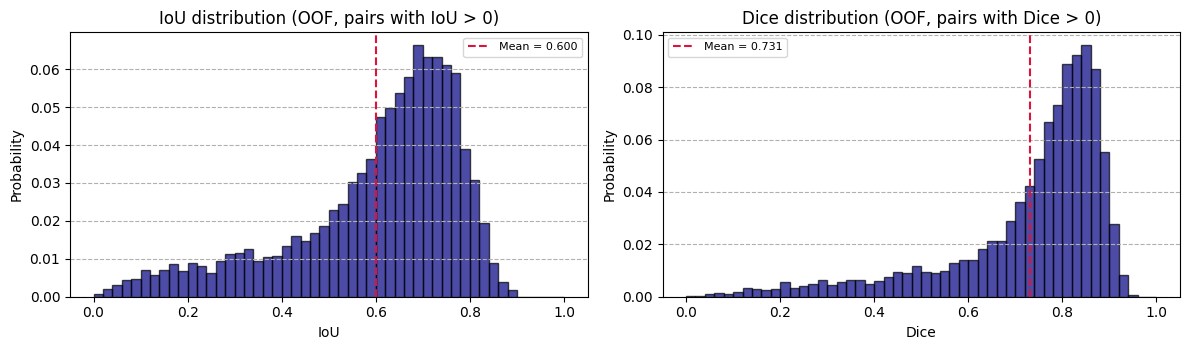

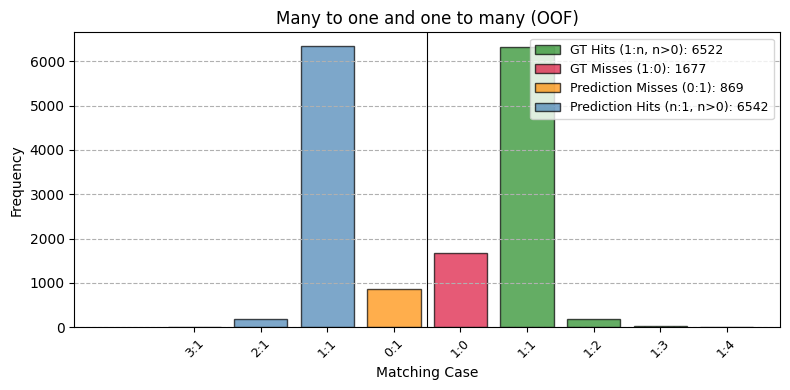

In [13]:
plt.figure(figsize=(12, 3.6))
plt.subplot(1, 2, 1)
plot_distribution(overlap["iou_matrix"], "IoU distribution (OOF, pairs with IoU > 0)", "IoU")
plt.subplot(1, 2, 2)
plot_distribution(overlap["dice_matrix"], "Dice distribution (OOF, pairs with Dice > 0)", "Dice")
plt.tight_layout()
plt.savefig(WORK / "oof_iou_dice.png", dpi=120)
plt.show()

plt.figure(figsize=(8, 4))
plot_m2n_counts(overlap, "Many to one and one to many (OOF)")
plt.tight_layout()
plt.savefig(WORK / "oof_relations.png", dpi=120)
plt.show()

The last view splits the OOF score by fold and by instrument site, the two letters before `h` at the end of the image name. A model that only works on some folds or some sites would show here. The fold numbers also show how much the score moves between groups of about 140 images, which is a useful scale for any difference between methods.

split group  images     PQ
 fold     0     139 0.4632
 fold     1     146 0.4551
 fold     2     132 0.4500
 fold     3     146 0.4583
 fold     4     144 0.4577
 site     B     118 0.4560
 site     C     125 0.4521
 site     L     127 0.4495
 site     M     125 0.4524
 site     T     110 0.4623
 site     U     102 0.4726


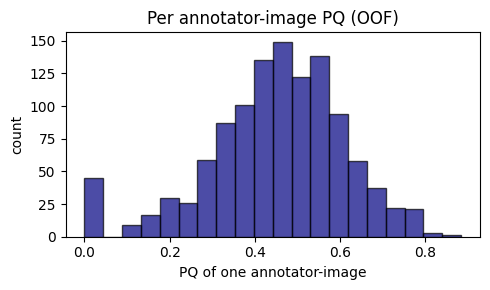

In [14]:
rows = []
for name, key in (("fold", lambda o: fold_of(o)), ("site", lambda o: o[-2])):
    for g in sorted({key(o) for o in gt}):
        sel = {o: gt[o] for o in gt if key(o) == g}
        rows.append({"split": name, "group": g, "images": len(sel), "PQ": round(pq(sel, oof_pred), 4)})
print(pd.DataFrame(rows).to_string(index=False))
plt.figure(figsize=(5, 3))
plt.hist(per_image.pq, bins=20, color="navy", alpha=0.7, edgecolor="black")
plt.xlabel("PQ of one annotator-image"); plt.ylabel("count"); plt.title("Per annotator-image PQ (OOF)")
plt.tight_layout(); plt.show()

## Summary

The notebook writes `submission.csv`, the out-of-fold predictions `oof_predictions.csv`, the fusion reference `fusion_ref.json` and the evaluation plots to `WORK`. With the saved maps and the saved quality head, the out-of-fold fusion reproduces 0.4571 PQ, and the test fusion reproduces the submitted file except for the two quiet-Sun images described in section 5. Two human annotators of the same image agree at only about 0.33 PQ under the same scorer, so the model matches a random annotator better than a second annotator does.